In [1]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd

In [2]:
b2 = rasterio.open("B2.tif")
b3 = rasterio.open("B3.tif")
b4 = rasterio.open("B4.tif")
b8 = rasterio.open("B8.tif")
b11 = rasterio.open("B11.tif")

In [3]:
print("CRS:", b8.crs)
print("Resolution:", b8.res)
print("Width:", b8.width)
print("Height:", b8.height)
print("Number of bands:", b8.count)
print("Data type:", b8.dtypes)
print("Bounds:", b8.bounds)
print("NoData value:", b8.nodata)
print("Transform:", b8.transform)

CRS: EPSG:32644
Resolution: (10.0, 10.0)
Width: 2569
Height: 2704
Number of bands: 1
Data type: ('uint16',)
Bounds: BoundingBox(left=404320.0, bottom=1428910.0, right=430010.0, top=1455950.0)
NoData value: None
Transform: | 10.00, 0.00, 404320.00|
| 0.00,-10.00, 1455950.00|
| 0.00, 0.00, 1.00|


In [4]:
red = b4.read(1)
green = b3.read(1)
blue = b2.read(1)
nir = b8.read(1)
swir = b11.read(1)

In [5]:
red.shape

(2704, 2569)

In [6]:
type(red)

numpy.ndarray

In [7]:
def stretch(image):
    p2, p98 = np.percentile(image, (2, 98))
    image = np.clip(image, p2, p98)
    return (image - p2) / (p98 - p2)

In [8]:
red_s = stretch(red)
green_s = stretch(green)
blue_s = stretch(blue)

In [9]:
rgb = np.dstack((red_s, green_s, blue_s))

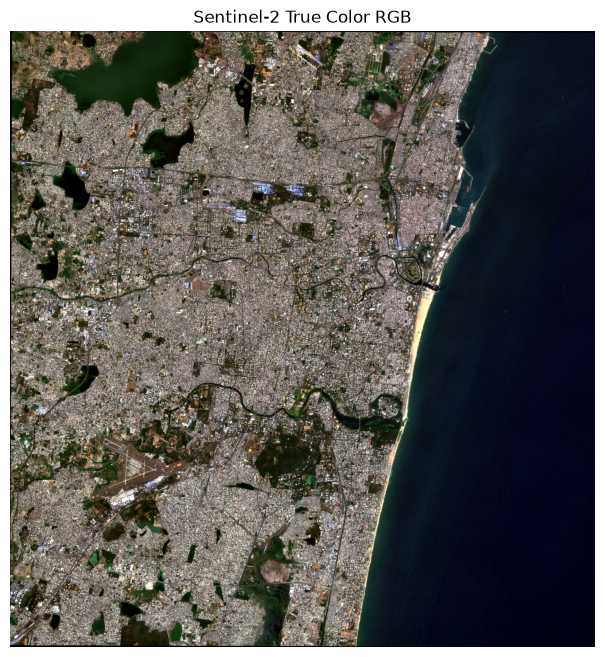

In [10]:
plt.figure(figsize=(10, 8))

plt.imshow(rgb)

plt.axis("off")

plt.title("Sentinel-2 True Color RGB")

plt.show()

In [11]:
nir_s = stretch(nir)

fcc = np.dstack((nir_s, red_s, green_s))

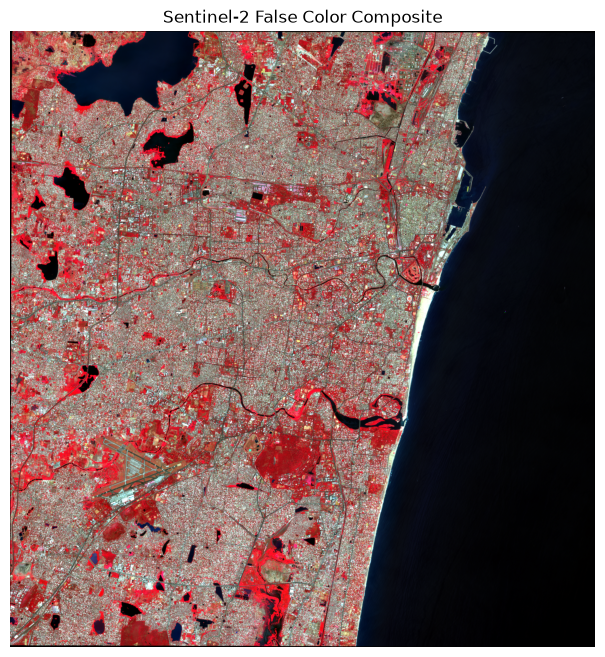

In [12]:
plt.figure(figsize=(10, 8))

plt.imshow(fcc)

plt.axis("off")

plt.title("Sentinel-2 False Color Composite")

plt.show()

In [13]:
chennai = gpd.read_file("Chennai.shp")

In [14]:
print(chennai.crs)
print(chennai.geometry.geom_type.value_counts())
print(chennai.shape)

EPSG:4326
Polygon    1
Name: count, dtype: int64
(1, 8)


In [15]:
print("Chennai CRS:", chennai.crs)
print("Raster CRS:", b8.crs)

Chennai CRS: EPSG:4326
Raster CRS: EPSG:32644


In [16]:
chennai_projected = chennai.to_crs(b8.crs)

In [17]:
from rasterio.mask import mask

In [18]:
geometries = chennai_projected.geometry.values

In [19]:
clipped, clipped_transform = mask(
    b8,
    geometries,
    crop=True
)

In [20]:
original = b8.read(1)

print("Original shape:", original.shape)
print("Clipped shape:", clipped[0].shape)

Original shape: (2704, 2569)
Clipped shape: (2013, 1422)


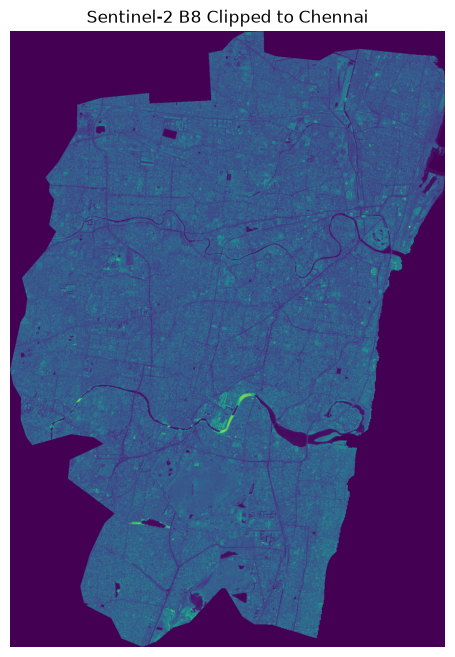

In [21]:
plt.figure(figsize=(8, 8))

plt.imshow(clipped[0])

plt.axis("off")

plt.title("Sentinel-2 B8 Clipped to Chennai")

plt.show()

In [22]:
from rasterio.warp import calculate_default_transform, reproject
from rasterio.enums import Resampling

In [23]:
dst_crs = "EPSG:4326"

In [24]:
transform, width, height = calculate_default_transform(
    b8.crs,
    dst_crs,
    b8.width,
    b8.height,
    *b8.bounds
)

In [25]:
reprojected = np.empty(
    (height, width),
    dtype=b8.dtypes[0]
)

In [26]:
reproject(
    source=b8.read(1),
    destination=reprojected,
    src_transform=b8.transform,
    src_crs=b8.crs,
    dst_transform=transform,
    dst_crs=dst_crs,
    resampling=Resampling.nearest
)

(array([[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]], shape=(2686, 2604), dtype=uint16),
 Affine(9.128583635451213e-05, 0.0, 80.11711151389089,
        0.0, -9.128583635451213e-05, 13.169318372257278))

In [27]:
print("B8 resolution:", b8.res)
print("B11 resolution:", b11.res)

B8 resolution: (10.0, 10.0)
B11 resolution: (20.0, 20.0)


In [29]:
b11_data = b11.read(1)

In [30]:
resampled_b11 = np.empty(
    (b8.height, b8.width),
    dtype=b11_data.dtype
)

In [31]:
reproject(
    source=b11_data,
    destination=resampled_b11,
    src_transform=b11.transform,
    src_crs=b11.crs,
    dst_transform=b8.transform,
    dst_crs=b8.crs,
    resampling=Resampling.bilinear
)

(array([[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]], shape=(2704, 2569), dtype=uint16),
 Affine(10.0, 0.0, 404320.0,
        0.0, -10.0, 1455950.0))

In [32]:
print("Original B11 shape:", b11_data.shape)
print("B8 shape:", (b8.height, b8.width))
print("Resampled B11 shape:", resampled_b11.shape)

Original B11 shape: (1353, 1285)
B8 shape: (2704, 2569)
Resampled B11 shape: (2704, 2569)
